# Гедонічна OLS: стартова ціна та фінальна орендна плата (H1)

## 0. Імпорт бібліотек і завантаження даних

In [1]:
import pandas as pd
import numpy as np
import plotnine as p9
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

df_raw = pd.read_csv("Prozoro_sales_cleaned.csv")

## 1. Формування вибірки

In [2]:
cols = [
    # ідентифікація та фільтри
    'Ідентифікатор аукціону',
    'Посилання на портал',
    'Статус аукціону',
    'Кадастровий номер',
    'Організатор',
    'Код організатора',
    # ціни
    'Дохід',
    'Виставлена вартість',
    'Нормативна грошова оцінка',
    'USD_rate',
    # характеристики ділянки та договору
    'Площа земельної ділянки, ГА',
    'lease_duration_years_int',
    'КВЦПЗ код класифікатора товару',
    'Тип власності',
    'Наявність обтяжень',
    'Вкотре виставляється',
    # розташування і час
    'область',
    'Дата аукціону',
    # лише для опису
    'Кількість пропозицій',
]

# аукціони з помилковою НГО на порталі (звірено з витягами про НГО в документах аукціону)
ngo_errors = [
    'LRE001-UA-20211101-42631', 'LRE001-UA-20240304-23505', 'LRE001-UA-20240429-52067',
    'LRE001-UA-20240513-49378', 'LRE001-UA-20240930-13467', 'LRE001-UA-20241112-47159',
    'LRE001-UA-20241114-46795', 'LRE001-UA-20250204-23052', 'LRE001-UA-20250513-77884',
    'LRE001-UA-20250702-48650', 'LRE001-UA-20250804-04383', 'LRE001-UA-20250813-94259',
    'LRE001-UA-20250912-09212', 'LRE001-UA-20251016-96951', 'LRE001-UA-20251110-89902',
    'LRE001-UA-20260204-79456', 'LRE001-UA-20260225-62456', 'LRE001-UA-20260409-11759',
    'LRE001-UA-20260508-60253', 'LRE001-UA-20260519-14778',
]
# інші проблемні аукціони
other_errors = [
    'LRE001-UA-20251031-97823',  # НГО неоднозначна: портал і витяг не узгоджуються зі стартом
    'LRE001-UA-20260416-13630',  # площа в датасеті 0,1515 га, на порталі 1,1515 га
]

completed = df_raw['Статус аукціону'] == 'Аукціон завершено'
positive_ngo = df_raw['Нормативна грошова оцінка'] > 0
not_excluded = ~df_raw['Ідентифікатор аукціону'].isin(ngo_errors + other_errors)

sample_flow = pd.DataFrame({
    'Крок': [
        'Початковий датасет',
        'Статус «Аукціон завершено»',
        'НГО > 0',
        'Без аукціонів з помилковою НГО або площею',
    ],
    'Залишилось': [
        len(df_raw),
        completed.sum(),
        (completed & positive_ngo).sum(),
        (completed & positive_ngo & not_excluded).sum(),
    ],
})
sample_flow['Виключено'] = (-sample_flow['Залишилось'].diff()).fillna(0).astype(int)
display(sample_flow)

df = df_raw.loc[completed & positive_ngo & not_excluded, cols].copy()

,Крок,Залишилось,Виключено
0,Початковий датасет,23371,0
1,Статус «Аукціон завершено»,22369,1002
2,НГО > 0,22275,94
3,Без аукціонів з помилковою НГО або площею,22253,22


## 2. Змінні, групування і списки

In [3]:
area = df['Площа земельної ділянки, ГА']
date = pd.to_datetime(df['Дата аукціону'])

# ціни за гектар
df['final_ha_usd'] = df['Дохід'] / area / df['USD_rate']
df['start_ha_usd'] = df['Виставлена вартість'] / area / df['USD_rate']
df['ngo_ha_usd'] = df['Нормативна грошова оцінка'] / area / df['USD_rate']
df['final_ha_uah'] = df['Дохід'] / area

# відношення
df['start_ngo'] = df['Виставлена вартість'] / df['Нормативна грошова оцінка']
df['final_start'] = df['Дохід'] / df['Виставлена вартість']

# логарифми
df['ln_final'] = np.log(df['final_ha_usd'])
df['ln_start'] = np.log(df['start_ha_usd'])
df['ln_ngo'] = np.log(df['ngo_ha_usd'])
df['ln_start_ngo'] = np.log(df['start_ngo'])
df['ln_area'] = np.log(area)

# час
df['year'] = date.dt.year.astype(str)
df['quarter'] = date.dt.to_period('Q').dt.to_timestamp()
df['quarter_num'] = date.dt.quarter

# згруповані категорії
kvcpz = df['КВЦПЗ код класифікатора товару'].map('{:.2f}'.format)
rare_kvcpz = kvcpz.value_counts()[lambda x: x < 30].index
df['kvcpz_group'] = kvcpz.where(~kvcpz.isin(rare_kvcpz), 'інше')

df['ownership_group'] = df['Тип власності'].where(
    df['Тип власності'].isin(['Комунальна', 'Державна']), 'Інше'
)

df['relisting_group'] = (
    df['Вкотре виставляється'].clip(upper=4).astype(str).replace({'4': '4+'})
)

df['oblast_group'] = df['область'].replace({
    'Луганська область': 'Донецька + Луганська',
    'Донецька область': 'Донецька + Луганська',
})

# громада-організатор (кластери і FE)
df['org'] = pd.factorize(df['Код організатора'])[0]

In [4]:
# списки змінних
num_cols = [
    'final_ha_usd',
    'start_ha_usd',
    'ngo_ha_usd',
    'start_ngo',
    'final_start',
    'Площа земельної ділянки, ГА',
    'lease_duration_years_int',
    'Кількість пропозицій',
]
log_cols = ['ln_final', 'ln_start', 'ln_ngo', 'ln_start_ngo', 'ln_area']

cat_cols = [
    'КВЦПЗ код класифікатора товару',
    'Тип власності',
    'Наявність обтяжень',
    'Вкотре виставляється',
    'область',
    'year',
]
cat_plot_cols = [
    'kvcpz_group',
    'ownership_group',
    'Наявність обтяжень',
    'relisting_group',
    'oblast_group',
    'year',
]

corr_cols = ['ln_final', 'ln_start', 'ln_ngo', 'ln_start_ngo', 'ln_area',
             'lease_duration_years_int']

spec_a = ['ln_start', 'ln_ngo', 'ln_area', 'lease_duration_years_int']
spec_b = ['ln_start_ngo', 'ln_ngo', 'ln_area', 'lease_duration_years_int']
cont = spec_b

# праві частини формул
base_oblast = df['oblast_group'].value_counts().idxmax()

controls = ('ln_start_ngo + ln_ngo + ln_area + lease_duration_years_int'
            ' + C(kvcpz_group) + C(ownership_group) + C(Q("Наявність обтяжень"))'
            f' + C(relisting_group) + C(oblast_group, Treatment("{base_oblast}")) + C(year)')

controls_org = ('ln_start_ngo + ln_ngo + ln_area + lease_duration_years_int'
                ' + C(kvcpz_group) + C(ownership_group) + C(Q("Наявність обтяжень"))'
                ' + C(relisting_group) + C(org) + C(year)')

# кластерні похибки за громадою
cluster = dict(cov_type='cluster', cov_kwds={'groups': df['org']})

## 3. Дескриптивний аналіз

### 3.1 Зведена статистика

In [5]:
def describe_stats(data, cols):
    d = data[cols]
    return pd.DataFrame({
        'Середнє': d.mean(),
        'Медіана': d.median(),
        'Ст. відхилення': d.std(),
        'Мін': d.min(),
        'P1': d.quantile(0.01),
        'P25': d.quantile(0.25),
        'P75': d.quantile(0.75),
        'P99': d.quantile(0.99),
        'Макс': d.max(),
        'Пропуски': d.isna().sum(),
    }).round(2)


describe_stats(df, num_cols + log_cols)

,Середнє,Медіана,Ст. відхилення,Мін,P1,P25,P75,P99,Макс,Пропуски
final_ha_usd,271.68,153.97,545.17,0.48,8.79,76.62,361.17,1226.23,27124.08,0
start_ha_usd,80.23,66.19,283.78,0.12,5.38,35.34,96.04,282.43,25065.94,0
ngo_ha_usd,739.74,579.13,4195.68,1.78,45.81,299.83,824.28,1838.23,315612.52,0
start_ngo,0.13,0.12,0.15,0.00,0.07,0.12,0.12,0.60,7.03,0
final_start,5.49,2.29,22.84,1.00,1.01,1.11,5.52,43.15,2261.68,0
"Площа земельної ділянки, ГА",11.16,7.00,37.99,0.01,0.14,2.28,14.62,92.30,3968.94,0
lease_duration_years_int,10.03,7.00,6.70,1.00,7.00,7.00,10.00,49.00,50.00,0
Кількість пропозицій,3.14,2.00,2.02,1.00,1.00,2.00,4.00,10.00,51.00,0
ln_final,5.03,5.04,1.11,-0.74,2.17,4.34,5.89,7.11,10.21,0
ln_start,4.01,4.19,0.83,-2.08,1.68,3.56,4.56,5.64,10.13,0


### 3.2 Розподіли

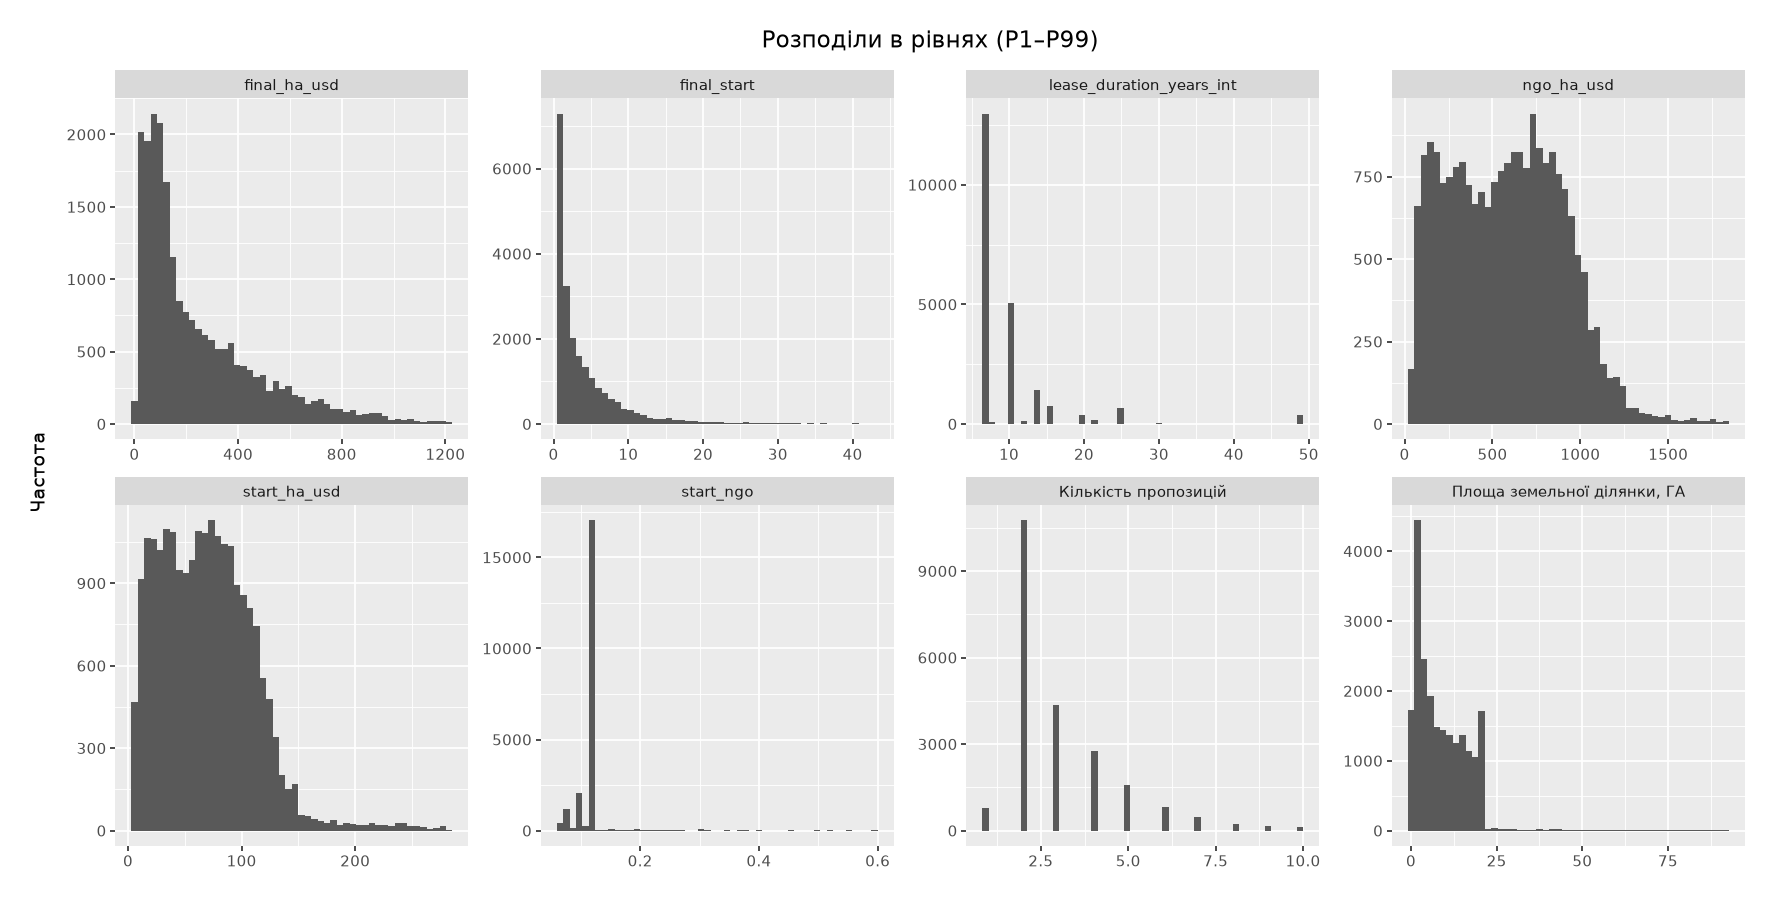

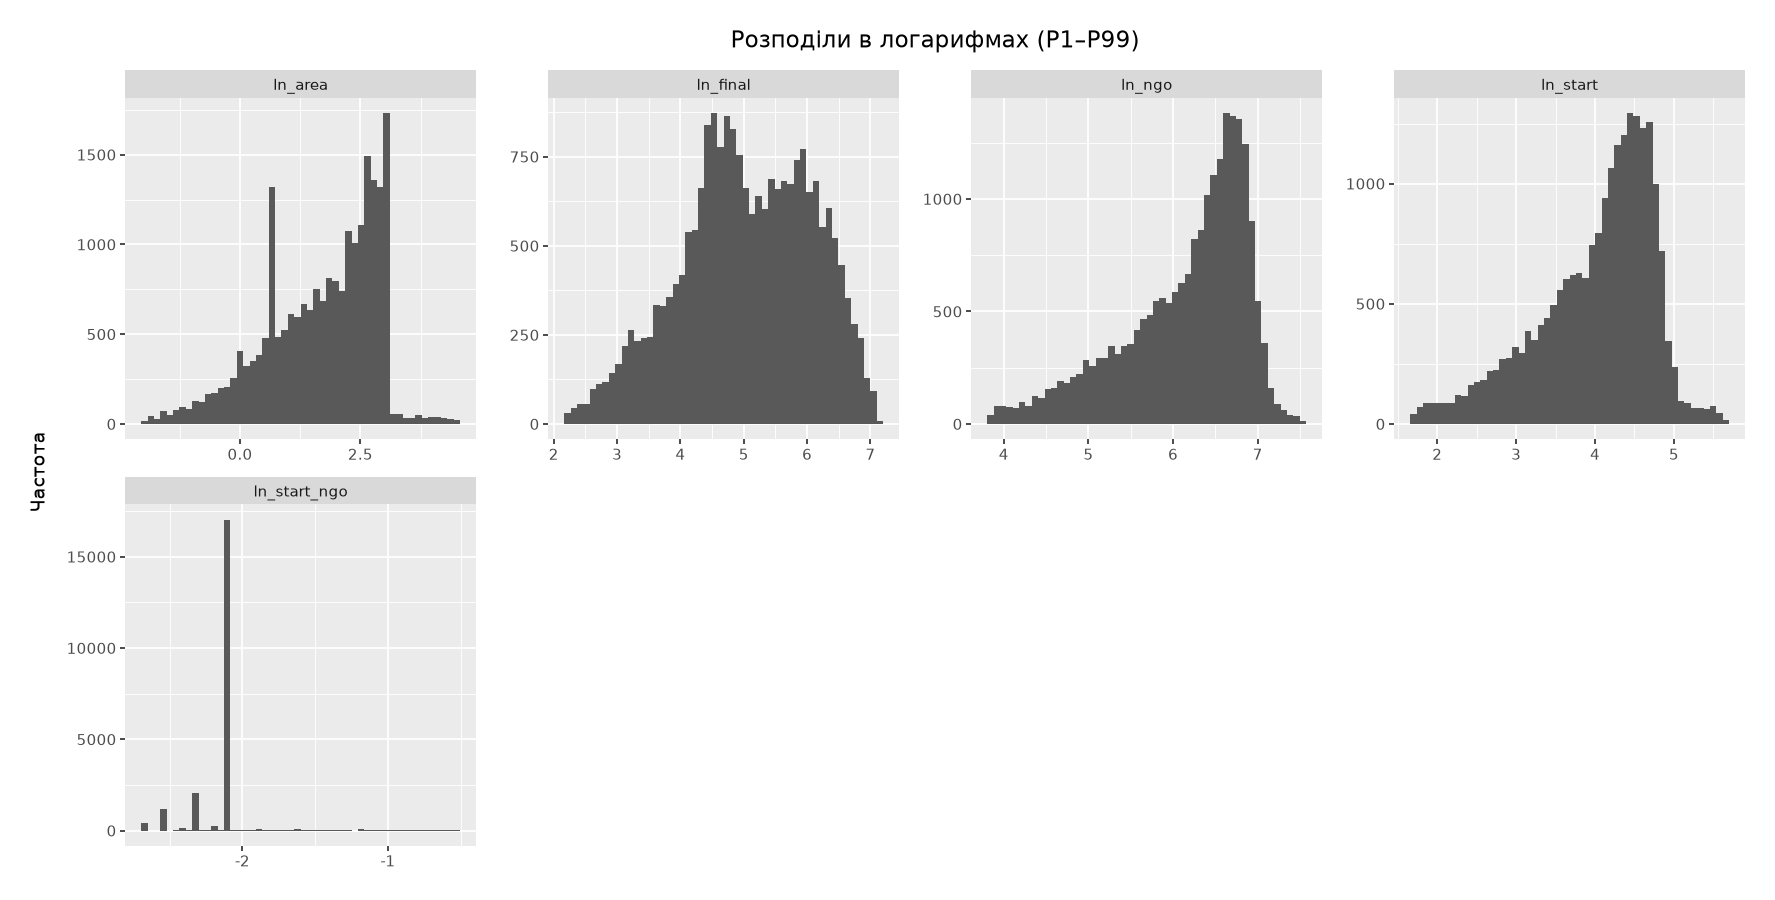

In [6]:
def plot_hist_grid(data, cols, title):
    long = data[cols].melt(var_name='variable', value_name='value')

    low = long.groupby('variable')['value'].transform(lambda x: x.quantile(0.01))
    high = long.groupby('variable')['value'].transform(lambda x: x.quantile(0.99))
    long = long[(long['value'] >= low) & (long['value'] <= high)]

    plot = (
        p9.ggplot(long, p9.aes('value'))
        + p9.geom_histogram(bins=50)
        + p9.facet_wrap('~variable', scales='free', ncol=4)
        + p9.labs(title=title, x='', y='Частота')
        + p9.theme(figure_size=(14, 7))
    )
    plot.show()


plot_hist_grid(df, num_cols, 'Розподіли в рівнях (P1–P99)')
plot_hist_grid(df, log_cols, 'Розподіли в логарифмах (P1–P99)')

### 3.3 Категоріальні змінні

In [7]:
def cat_table(data, col):
    table = data.groupby(col).agg(
        N=('final_ha_usd', 'size'),
        median_final_usd=('final_ha_usd', 'median'),
    )
    table['share_%'] = (table['N'] / table['N'].sum() * 100).round(1)
    table['median_final_usd'] = table['median_final_usd'].round(1)
    return table.sort_values('N', ascending=False)


for col in cat_cols:
    print(col)
    display(cat_table(df, col))

КВЦПЗ код класифікатора товару


,N,median_final_usd,share_%
КВЦПЗ код класифікатора товару,,,
1.01,17520,155.0,78.7
1.00,1661,131.3,7.5
1.02,1068,293.9,4.8
1.03,897,150.7,4.0
1.13,549,127.1,2.5
1.10,127,143.7,0.6
1.08,105,30.9,0.5
1.05,98,116.0,0.4
1.09,87,570.5,0.4


Тип власності


,N,median_final_usd,share_%
Тип власності,,,
Комунальна,20847,152.7,93.7
Державна,1183,142.8,5.3
Невизначено,131,241.1,0.6
Приватна,87,341.0,0.4
Сумісна,5,231.0,0.0


Наявність обтяжень


,N,median_final_usd,share_%
Наявність обтяжень,,,
Ні,18106,154.2,81.4
Так,4147,151.9,18.6


... (2 outputs left out)

область


,N,median_final_usd,share_%
область,,,
Одеська область,3106,115.8,14.0
Львівська область,2015,159.5,9.1
Черкаська область,1749,183.1,7.9
Сумська область,1695,149.8,7.6
Волинська область,1543,74.5,6.9
Полтавська область,1536,381.2,6.9
Житомирська область,1269,96.7,5.7
Чернігівська область,957,115.2,4.3
Тернопільська область,930,324.6,4.2


year


,N,median_final_usd,share_%
year,,,
2025,7084,152.5,31.8
2024,6111,130.6,27.5
2023,3977,142.4,17.9
2026,3730,174.6,16.8
2022,894,308.2,4.0
2021,457,367.5,2.1


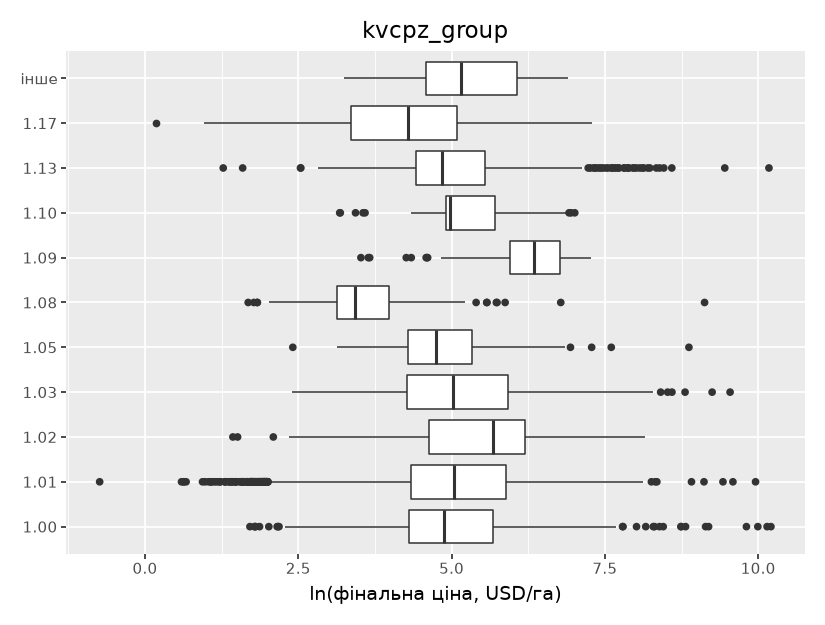

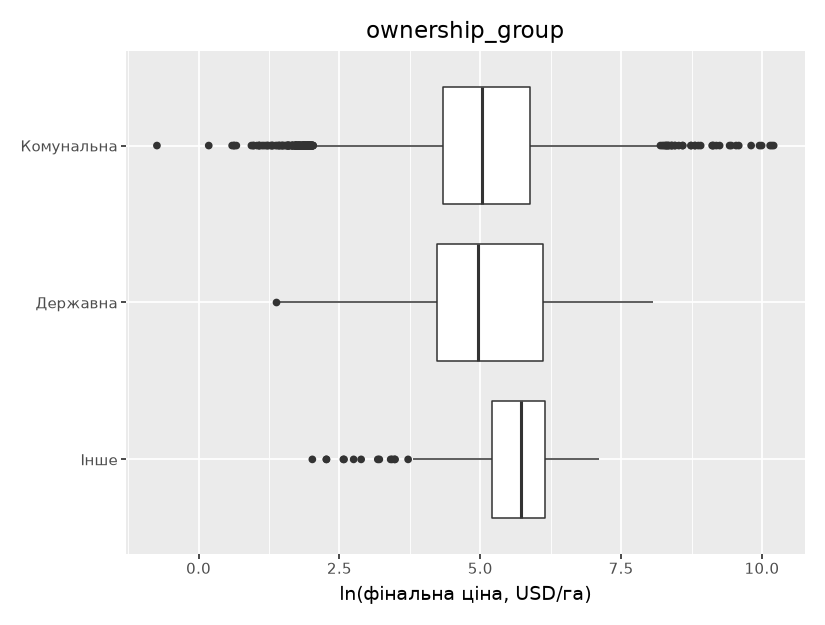

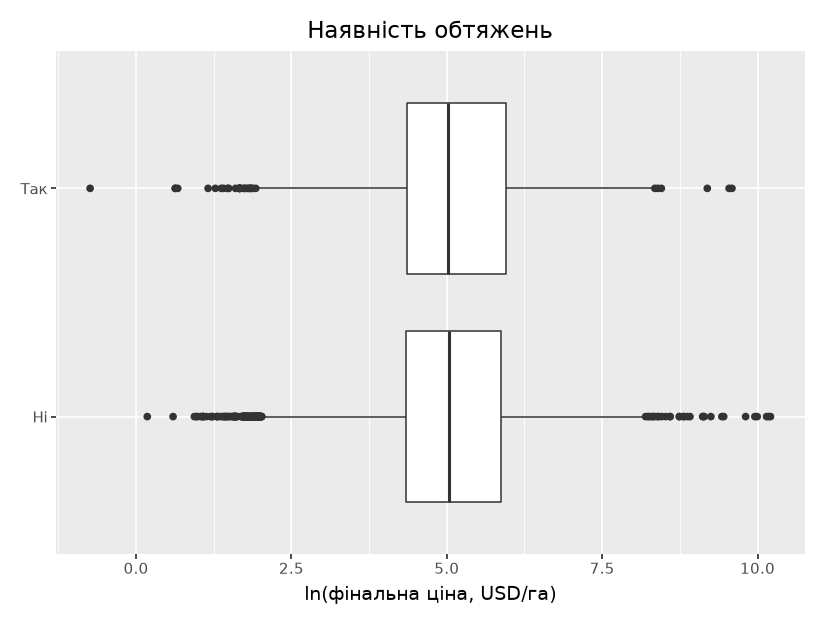

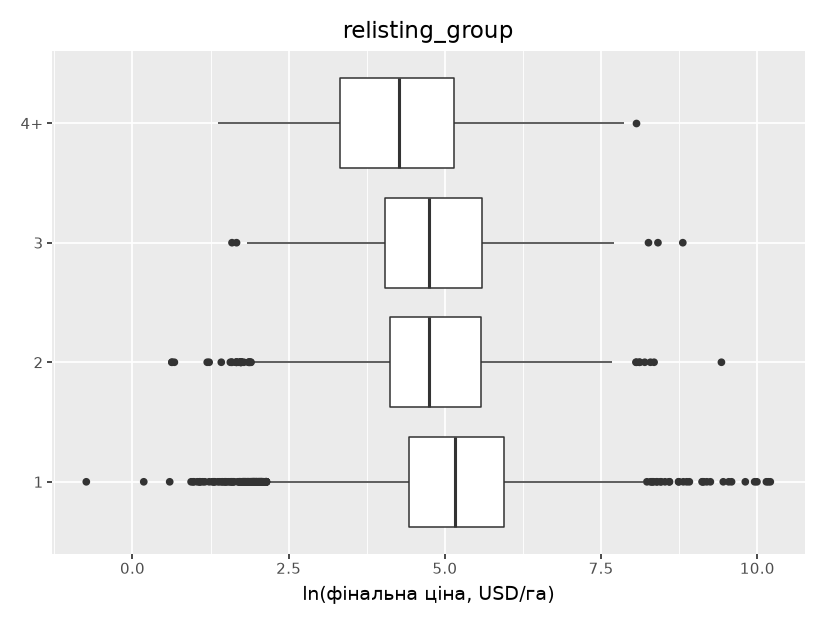

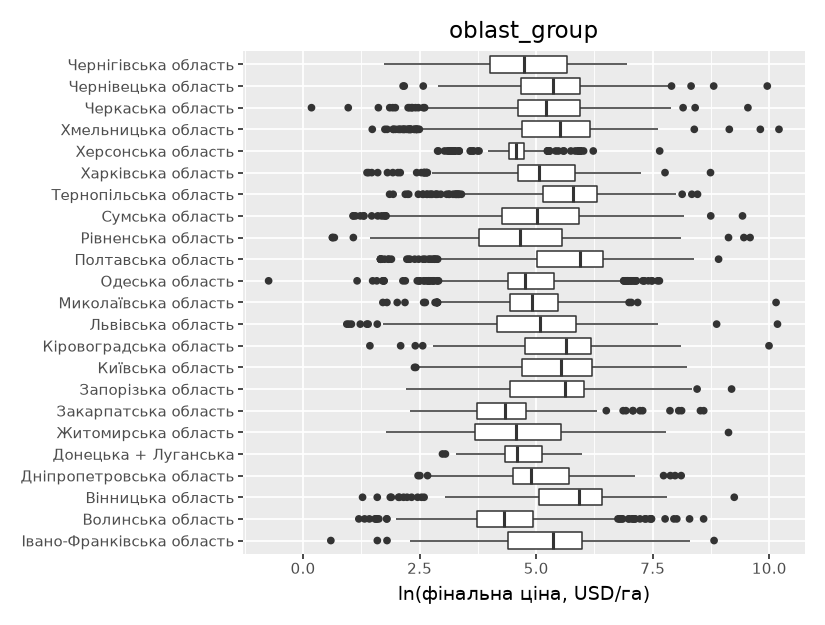

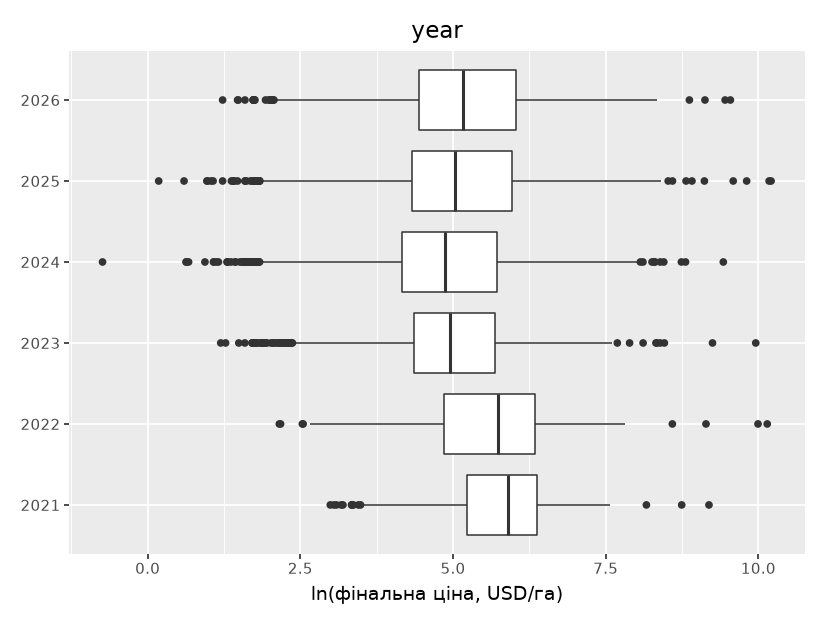

In [8]:
for col in cat_plot_cols:
    plot = (
        p9.ggplot(df, p9.aes(col, 'ln_final'))
        + p9.geom_boxplot()
        + p9.coord_flip()
        + p9.labs(title=col, x='', y='ln(фінальна ціна, USD/га)')
    )
    plot.show()

### 3.4 Кореляції

In [9]:
pearson = df[corr_cols].corr(method='pearson').round(2)
spearman = df[corr_cols].corr(method='spearman').round(2)

display(pearson)
display(spearman)

,ln_final,ln_start,ln_ngo,ln_start_ngo,ln_area,lease_duration_years_int
ln_final,1.00,0.52,0.49,0.09,0.07,-0.06
ln_start,0.52,1.00,0.92,0.19,-0.09,-0.02
ln_ngo,0.49,0.92,1.00,-0.21,-0.10,0.02
ln_start_ngo,0.09,0.19,-0.21,1.00,0.03,-0.09
ln_area,0.07,-0.09,-0.10,0.03,1.00,0.01
lease_duration_years_int,-0.06,-0.02,0.02,-0.09,0.01,1.00


,ln_final,ln_start,ln_ngo,ln_start_ngo,ln_area,lease_duration_years_int
ln_final,1.00,0.46,0.41,0.11,0.08,-0.09
ln_start,0.46,1.00,0.92,0.13,-0.10,-0.06
ln_ngo,0.41,0.92,1.00,-0.09,-0.11,-0.04
ln_start_ngo,0.11,0.13,-0.09,1.00,0.02,0.01
ln_area,0.08,-0.10,-0.11,0.02,1.00,0.11
lease_duration_years_int,-0.09,-0.06,-0.04,0.01,0.11,1.00


### 3.5 Співвідношення старт / НГО

In [10]:
# частка аукціонів за округленим співвідношенням старт / НГО, %
start_ngo_pct = (df['start_ngo'] * 100).round()
start_ngo_pct.value_counts(normalize=True).head(10).round(4)

start_ngo
12.0    0.7651
10.0    0.0925
8.0     0.0530
7.0     0.0189
11.0    0.0115
9.0     0.0064
3.0     0.0042
20.0    0.0042
30.0    0.0031
15.0    0.0028
Name: proportion, dtype: float64

### 3.6 Фінальна ціна, старт і НГО

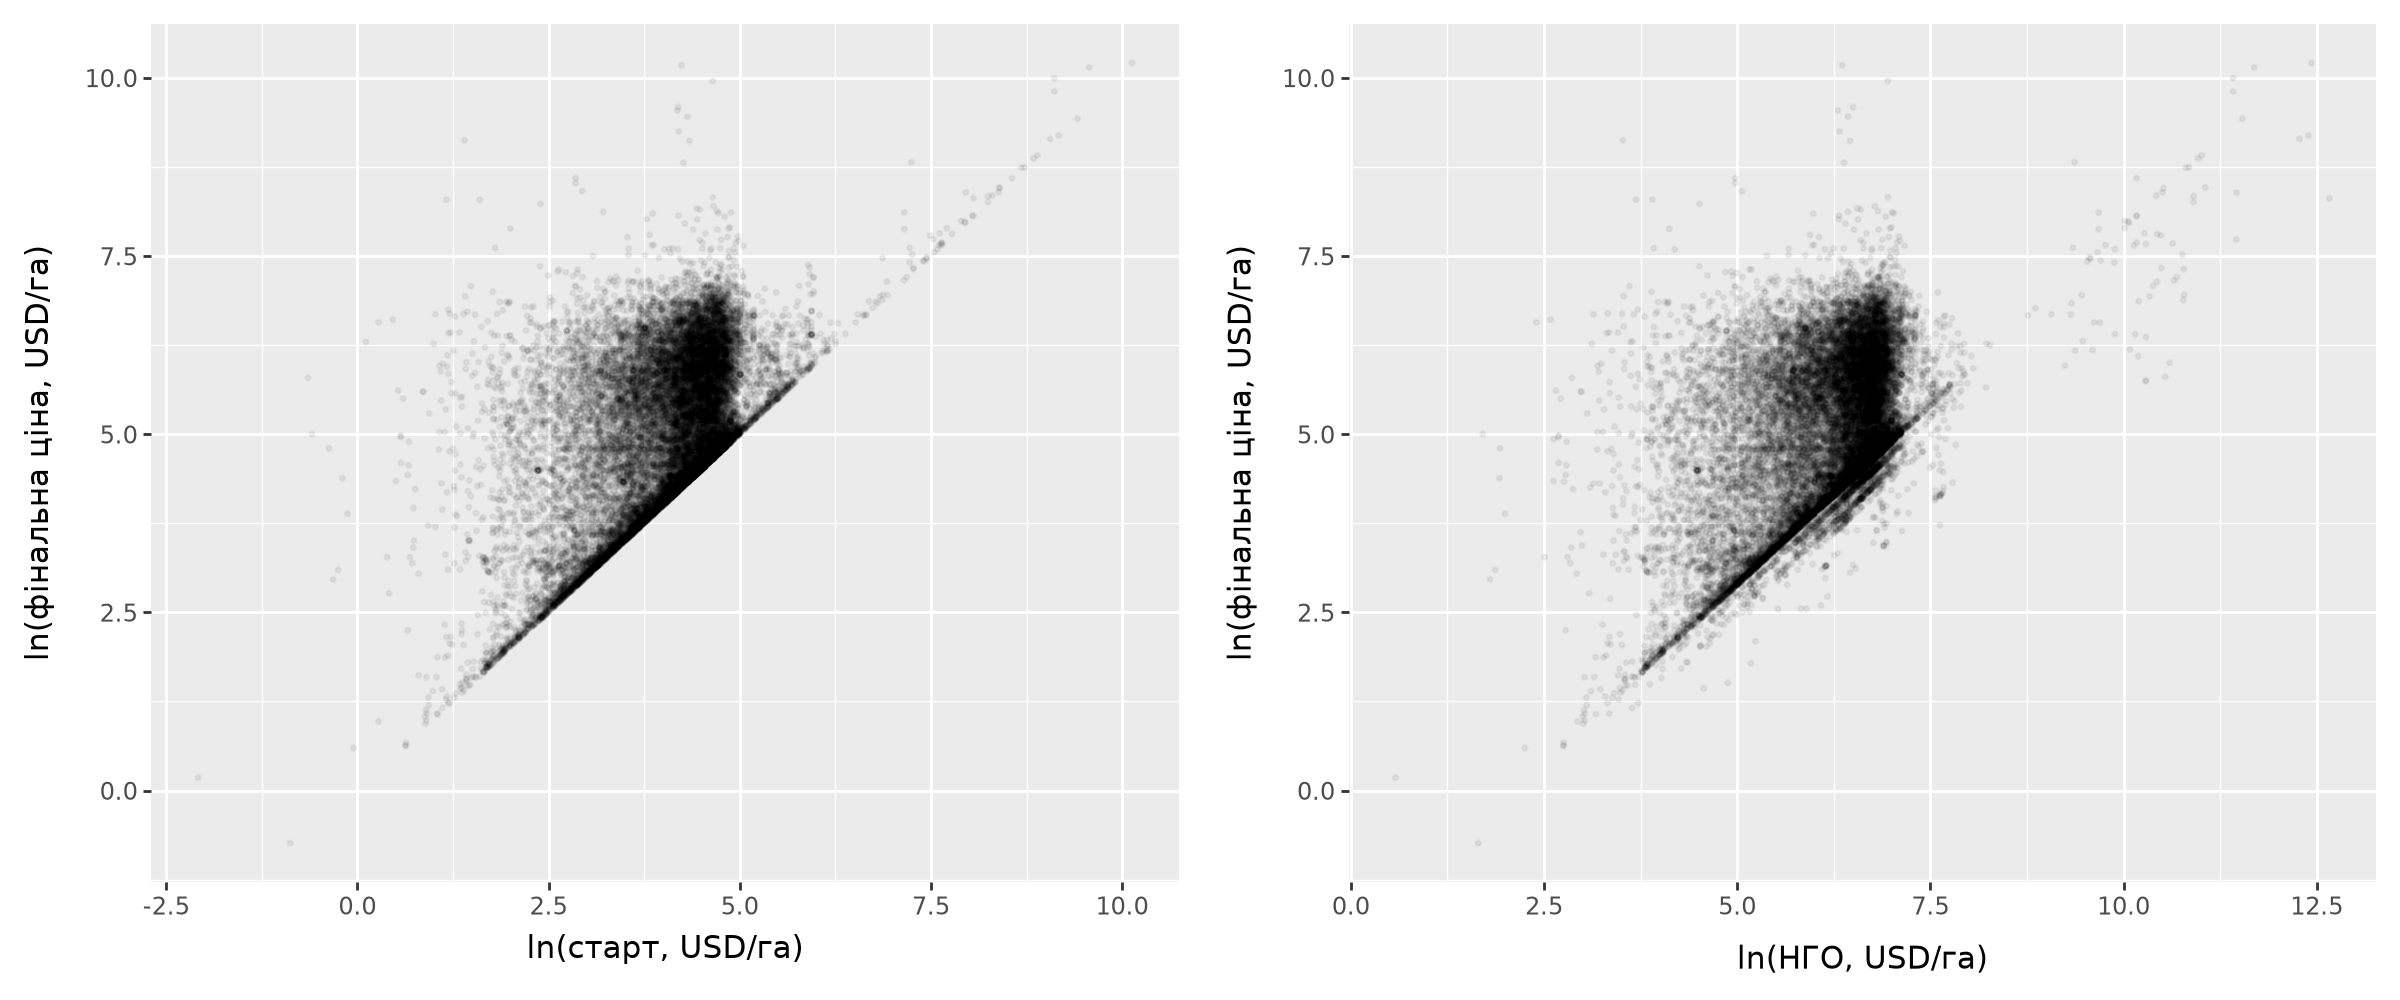

In [11]:
p_start = (
    p9.ggplot(df, p9.aes(x='ln_start', y='ln_final'))
    + p9.geom_point(alpha=0.05, size=0.5)
    + p9.labs(x='ln(старт, USD/га)', y='ln(фінальна ціна, USD/га)')
)

p_ngo = (
    p9.ggplot(df, p9.aes(x='ln_ngo', y='ln_final'))
    + p9.geom_point(alpha=0.05, size=0.5)
    + p9.labs(x='ln(НГО, USD/га)', y='ln(фінальна ціна, USD/га)')
)

(p_start | p_ngo) + p9.theme(figure_size=(12, 5))

### 3.7 Динаміка в часі

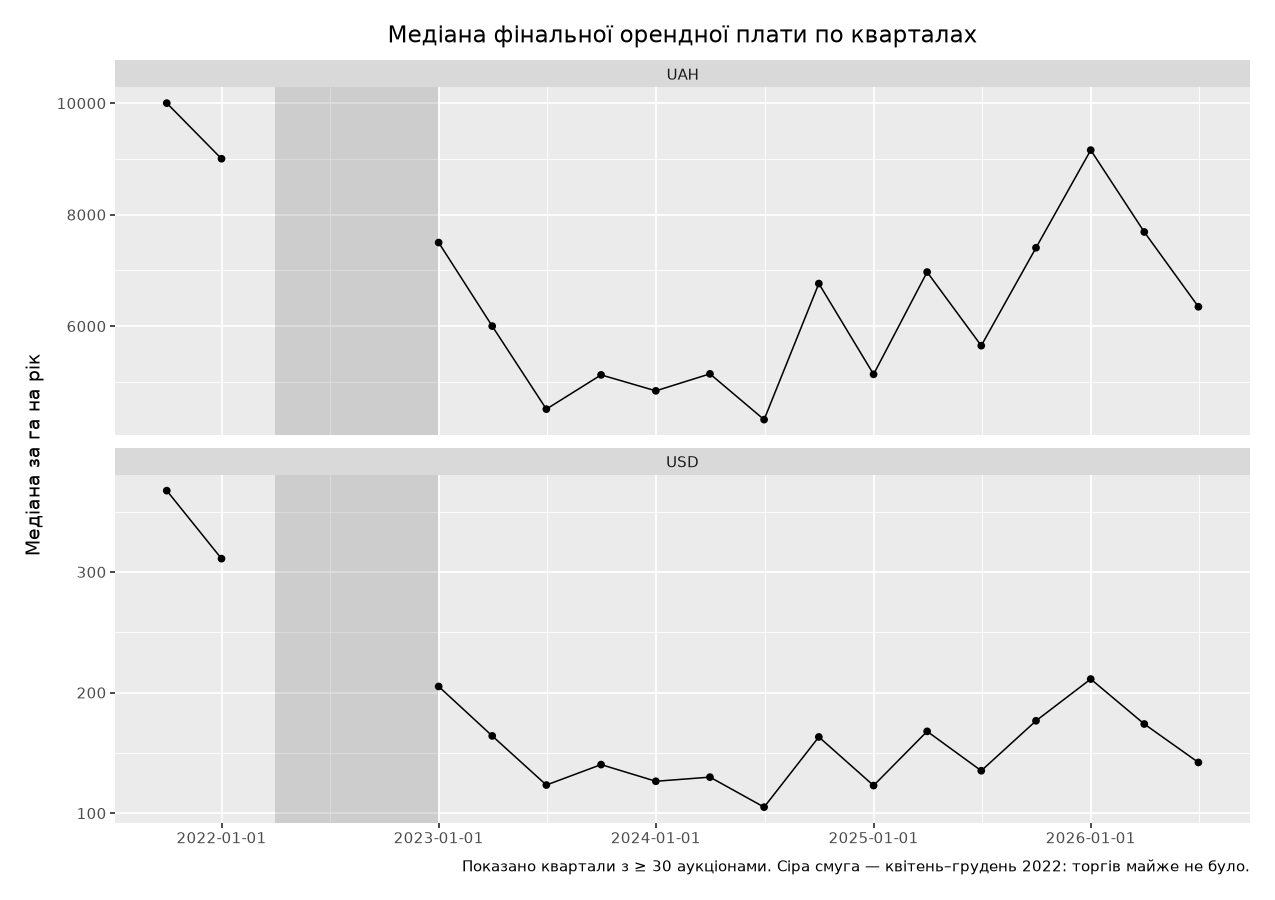

In [12]:
quarterly = df.groupby('quarter').agg(
    USD=('final_ha_usd', 'median'),
    UAH=('final_ha_uah', 'median'),
    N=('final_ha_usd', 'size'),
).reset_index()

# прибираємо квартали з малою кількістю аукціонів
quarterly = quarterly[quarterly['N'] >= 30]

# окремі відрізки лінії до і після перерви, щоб лінія не з'єднувала розрив
quarterly['period'] = np.where(quarterly['quarter'] < '2022-04-01', 'до', 'після')

quarterly_long = quarterly.melt(
    id_vars=['quarter', 'period', 'N'],
    value_vars=['USD', 'UAH'],
    var_name='currency',
    value_name='median_price',
)

(
    p9.ggplot(quarterly_long, p9.aes('quarter', 'median_price', group='period'))
    + p9.annotate('rect',
                  xmin=pd.Timestamp('2022-04-01'), xmax=pd.Timestamp('2022-12-31'),
                  ymin=-np.inf, ymax=np.inf, alpha=0.2)
    + p9.geom_line()
    + p9.geom_point()
    + p9.facet_wrap('~currency', scales='free_y', ncol=1)
    + p9.labs(
        title='Медіана фінальної орендної плати по кварталах',
        x='', y='Медіана за га на рік',
        caption='Показано квартали з ≥ 30 аукціонами. Сіра смуга — квітень–грудень 2022: торгів майже не було.',
    )
    + p9.theme(figure_size=(10, 7))
)

## 4. Попередні тести (preliminary tests)

| № | Пункт | Тести | Результати | Рішення |
|---|---|---|---|---|
| 1 | Функціональна форма | Порівняння розподілів у рівнях і логарифмах; тест Бокса-Кокса | Рівні сильно скошені вправо, логарифми близькі до симетричних; $\hat\lambda = 0{,}035$ (95% ДІ ≈ [0,025; 0,04]), $\ell_p(\hat\lambda) - \ell_p(0) = 25{,}5$ — формально $\lambda = 0$ відхиляється через великий $n$ | log-log специфікація |
| 2 | Викиди та аномалії | Перцентилі; звірка НГО з витягами про НГО в документах аукціонів (розділ 1) | 20 аукціонів з помилковою НГО на порталі (×10, ×100, ÷10, ÷100), 1 з неоднозначною НГО, 1 з помилкою площі; 38 з офіційною НГО < 1 000 грн/га збігаються з витягами | 22 аукціони виключено (22 275 → 22 253); решту залишено |
| 3 | Мультиколінеарність | Кореляційна матриця; VIF для ($\ln S$, $\ln NGO$) і для ($\ln(S/NGO)$, $\ln NGO$) | $\text{corr}(\ln S, \ln NGO) = 0{,}92$; VIF: A — 6,46 / 6,48, B — 1,06 / 1,06; площа і строк ≈ 1,01 | Основна специфікація A ($\ln S$ + $\ln NGO$): VIF < 10, а $\hat\beta_1$ і його SE однакові в A і B; B використано для загальної еластичності за НГО |
| 4 | Ефекти області | Тест Вальда сумісної значущості dummy областей | $W = 1054{,}1$, $df = 22$, $p < 0{,}001$; ефекти від −39,8% (Херсонська) до +180,8% (Вінницька) відносно Одеської області | FE області потрібні |
| 5 | Ефекти громади-організатора: FE чи RE | Тест Мундлака (кластерні похибки) | $W = 20{,}2$, $df = 4$, $p < 0{,}001$; $\hat\beta_1$: 0,490 → 0,553 | RE неконзистентна → FE громади (FE області поглинаються) |
| 6 | Варіація всередині громад | Розклад дисперсії $\ln(S/NGO)$ на між- і всередині-групову | 37,9% варіації всередині громад; 975 громад, 106 з одним аукціоном | Варіації достатньо для FE громади |
| 7 | Ефекти часу | Тест Вальда для dummy року і dummy кварталу | Рік: $W = 99{,}0$, $df = 5$, $p < 0{,}001$ (2023–2024: −41% до 2021); квартал: $W = 15{,}0$, $df = 3$, $p = 0{,}002$ (IV квартал +12,9%) | FE року + FE кварталу |

### Специфікація для попередніх тестів

Усі тести розділу 4 оцінено на тій самій специфікації, що й основна модель: $\ln S$, $\ln NGO$, $\ln A$, строк оренди, КВЦПЗ, тип власності, обтяження, номер виставлення, ефекти року та кварталу; ефекти області (4.1–4.4) або організатора (4.5).

In [13]:
# специфікація основної моделі для всіх попередніх тестів
cont = spec_a

hedonic = ('ln_ngo + ln_area + lease_duration_years_int'
           ' + C(kvcpz_group) + C(ownership_group) + C(Q("Наявність обтяжень"))'
           ' + C(relisting_group) + C(year) + C(quarter_num)')
fe_oblast = f' + C(oblast_group, Treatment("{base_oblast}"))'

controls = 'ln_start + ' + hedonic + fe_oblast          # FE області
controls_org = 'ln_start + ' + hedonic + ' + C(org)'    # FE організатора

### 4.1 Тест Бокса-Кокса: вибір функціональної форми

Перетворення залежної змінної:

$$
y^{(\lambda)} = \begin{cases} \dfrac{y^{\lambda} - 1}{\lambda}, & \lambda \neq 0 \\[4pt] \ln y, & \lambda = 0 \end{cases}
$$

$\lambda = 1$ — рівні, $\lambda = 0$ — логарифм. Для кожного $\lambda$ оцінюється регресія $y^{(\lambda)} = X'\beta + \varepsilon$ на регресорах основної моделі і рахується профільна log-правдоподібність:

$$
\ell_p(\lambda) = -\frac{n}{2}\ln\frac{RSS(\lambda)}{n} + (\lambda - 1)\sum_{i=1}^{n}\ln y_i
$$

- $y_i$ — фінальна орендна плата, USD/га;
- $n$ — кількість аукціонів;
- $RSS(\lambda)$ — сума квадратів залишків регресії $y^{(\lambda)}$ на $X$;
- $(\lambda - 1)\sum \ln y_i$ — якобіан перетворення: зводить правдоподібності для різних $\lambda$ до шкали вихідного $y$, щоб їх можна було порівнювати.

Оцінка: $\hat\lambda = \arg\max_\lambda \ell_p(\lambda)$.

Тест $H_0: \lambda = 0$ (логарифм) — тест відношення правдоподібностей:

$$
LR = 2\big[\ell_p(\hat\lambda) - \ell_p(0)\big] \sim \chi^2(1)
$$

$H_0$ не відхиляється на рівні 5%, якщо $\ell_p(\hat\lambda) - \ell_p(0) < 1{,}92$. 95% довірчий інтервал: усі $\lambda$, для яких $\ell_p(\hat\lambda) - \ell_p(\lambda) < 1{,}92$.

Обмеження: тест припускає незалежні, гомоскедастичні та нормальні похибки. При $n \approx 22$ тис. і кореляції всередині громад інтервал буде занадто вузьким, тому близьке до 0 значення $\hat\lambda$ трактується як підтримка логарифмічної форми.

In [14]:
y = df['final_ha_usd']
lams = np.round(np.arange(0, 0.105, 0.005), 3)


def loglik(lam):
    y_bc = np.log(y) if lam == 0 else (y**lam - 1) / lam
    rss = smf.ols('y_bc ~ ' + controls, data=df.assign(y_bc=y_bc)).fit().ssr
    return -len(y) / 2 * np.log(rss / len(y)) + (lam - 1) * np.log(y).sum()


bc = pd.DataFrame({'lambda': lams, 'loglik': [loglik(l) for l in lams]})
best = bc.loc[bc['loglik'].idxmax()]
ci = bc.loc[bc['loglik'] > best['loglik'] - 1.92, 'lambda']
diff_to_log = best['loglik'] - bc.loc[bc['lambda'] == 0, 'loglik'].iloc[0]

print(f"λ = {best['lambda']}, 95% ДІ ≈ [{ci.min()}; {ci.max()}], ℓ(λ̂) − ℓ(0) = {diff_to_log:.1f}")

λ = 0.035, 95% ДІ ≈ [0.025; 0.04], ℓ(λ̂) − ℓ(0) = 25.5


### 4.2 Мультиколінеарність: VIF

Коефіцієнт роздування дисперсії для регресора $x_j$:

$$
\text{VIF}_j = \frac{1}{1 - R_j^2}
$$

- $R_j^2$ — коефіцієнт детермінації регресії $x_j$ на всі інші неперервні регресори (з константою);
- VIF показує, у скільки разів дисперсія $\hat\beta_j$ більша, ніж за відсутності кореляції з іншими регресорами; $\sqrt{\text{VIF}}$ — у скільки разів більша стандартна похибка.

Порогові значення: VIF > 5 — помірна, VIF > 10 — серйозна мультиколінеарність.

Порівнюються дві специфікації:
- **A:** $\ln S$, $\ln NGO$, $\ln A$, строк оренди;
- **B:** $\ln(S/NGO)$, $\ln NGO$, $\ln A$, строк оренди.

Специфікація B — перепараметризація A: $\beta_1 \ln S + \beta_2 \ln NGO = \beta_1 \ln(S/NGO) + (\beta_1 + \beta_2)\ln NGO$. Підгонка моделі однакова, змінюється лише кореляція між регресорами.

Обмеження: VIF враховує лише неперервні регресори, без фіксованих ефектів області та року.

In [15]:
def vif_table(data, cols):
    X = add_constant(data[cols])
    return pd.Series(
        [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
        index=cols, name='VIF'
    ).round(2)


pd.concat([vif_table(df, spec_a).rename('A: ln S + ln NGO'),
           vif_table(df, spec_b).rename('B: ln(S/NGO) + ln NGO')], axis=1)

,A: ln S + ln NGO,B: ln(S/NGO) + ln NGO
ln_start,6.46,NaN
ln_ngo,6.48,1.06
ln_area,1.01,1.01
lease_duration_years_int,1.01,1.01
ln_start_ngo,NaN,1.06


### 4.3 Фіксовані ефекти області: тест Вальда

Чи відрізняється рівень цін між областями за інших рівних умов? Модель:

$$
\ln y_i = X_i'\beta + \sum_{r=2}^{R} \gamma_r D_{ir} + \tau_{t(i)} + \varepsilon_i
$$

- $y_i$ — фінальна орендна плата, USD/га;
- $X_i$ — регресори основної моделі ($\ln S$, $\ln NGO$, $\ln A$, строк оренди, КВЦПЗ, тип власності, обтяження, повторне виставлення);
- $D_{ir}$ — dummy області $r$ (базова — найчисленніша область), $R = 23$;
- $\tau_{t(i)}$ — ефекти року та кварталу.

Гіпотеза: $H_0: \gamma_2 = \dots = \gamma_R = 0$ (рівень цін однаковий в усіх областях).

$$
W = \hat\gamma'\,\big[\widehat{\text{Var}}(\hat\gamma)\big]^{-1}\hat\gamma \sim \chi^2(R - 1)
$$

$\widehat{\text{Var}}(\hat\gamma)$ — кластерно-робастна коваріаційна матриця (кластер — громада-організатор), що враховує кореляцію аукціонів однієї громади та гетероскедастичність.

In [16]:
m_oblast = smf.ols('ln_final ~ ' + controls, data=df).fit(**cluster)

idx = [i for i, name in enumerate(m_oblast.params.index) if name.startswith('C(oblast_group')]
print(f'Базова область: {base_oblast}')
print(m_oblast.wald_test(np.eye(len(m_oblast.params))[idx], scalar=True))

# різниця цін з базовою областю, %
oblast_effects = (np.exp(m_oblast.params.iloc[idx]) - 1).mul(100).round(1).sort_values()
oblast_effects.index = oblast_effects.index.str.extract(r'\[T\.(.*)\]')[0]
oblast_effects

Базова область: Одеська область
<Wald test (chi2): statistic=1054.0544929742402, p-value=6.051264578206004e-209, df_denom=22>


0
Херсонська область           -39.8
Донецька + Луганська          -7.0
Волинська область             -1.1
Миколаївська область          11.4
Закарпатська область          21.7
Дніпропетровська область      23.7
Житомирська область           27.6
Чернігівська область          37.9
Харківська область            38.7
Запорізька область            42.9
Сумська область               58.6
Рівненська область            67.7
Львівська область             74.8
Черкаська область             75.5
Кіровоградська область        82.1
Івано-Франківська область     87.7
Чернівецька область          101.1
Хмельницька область          118.4
Київська область             120.1
Тернопільська область        154.0
Полтавська область           157.9
Вінницька область            180.8
dtype: float64

### 4.4 Ефекти громади: фіксовані чи випадкові (тест Мундлака)

Модель з ефектом громади-організатора $g$:

$$
\ln y_{ig} = X_{ig}'\beta + \gamma_{r(g)} + \tau_t + u_g + \varepsilon_{ig}
$$

- $X_{ig}$ — регресори основної моделі;
- $\gamma_{r(g)}$, $\tau_t$ — фіксовані ефекти області, року та кварталу;
- $u_g$ — ефект громади: відхилення рівня цін громади від середнього по області.

Випадкові ефекти (RE) коректні лише якщо $\text{Cov}(u_g, X_{ig}) = 0$. Тест Мундлака перевіряє це припущення: до моделі додаються середні по громаді неперервних регресорів $\bar X_g$,

$$
\ln y_{ig} = X_{ig}'\beta + \bar X_g'\pi + \gamma_{r(g)} + \tau_t + a_g + \varepsilon_{ig},
$$

і перевіряється $H_0: \pi = 0$ тестом Вальда з кластерними за громадою похибками:

$$
W = \hat\pi'\,\big[\widehat{\text{Var}}(\hat\pi)\big]^{-1}\hat\pi \sim \chi^2(k)
$$

- $H_0$ не відхиляється → ефекти громад не корелюють з регресорами → достатньо FE області та кластеризації за громадою;
- $H_0$ відхиляється → RE неконзистентна → потрібні FE громади.

Додатково порівнюється $\hat\beta_1$ (коефіцієнт при $\ln S$) у моделях без і з $\bar X_g$, а також частка варіації $\ln(S/NGO)$ всередині громад: FE громади використовує лише її, а саме незалежна від НГО частина старту ідентифікує $\beta_1$.

In [17]:
for v in cont:
    df[v + '_mean'] = df.groupby('org')[v].transform('mean')
means = [v + '_mean' for v in cont]

m_mund = smf.ols('ln_final ~ ' + controls + ' + ' + ' + '.join(means), data=df).fit(**cluster)

# тест Мундлака: H0 — коефіцієнти при середніх = 0
print(m_mund.wald_test(', '.join(f'{v} = 0' for v in means), scalar=True))

# як змінюються коефіцієнти
print(pd.DataFrame({
    'без середніх': m_oblast.params[cont],
    'Мундлак': m_mund.params[cont],
}).round(3))

# частка варіації ln(S/NGO) всередині громад
x = df['ln_start_ngo']
x_mean = df.groupby('org')['ln_start_ngo'].transform('mean')
within = ((x - x_mean)**2).sum()
print(f'Варіація всередині громад: {within / ((x - x.mean())**2).sum():.1%}')
print(f'Громад: {df["org"].nunique()}, з одним аукціоном: {(df["org"].value_counts() == 1).sum()}')

<Wald test (chi2): statistic=20.227300339998056, p-value=0.0004503542457314026, df_denom=4>
                          без середніх  Мундлак
ln_start                         0.490    0.553
ln_ngo                           0.206    0.079
ln_area                          0.153    0.150
lease_duration_years_int        -0.007   -0.010
Варіація всередині громад: 37.9%
Громад: 975, з одним аукціоном: 106


### 4.5 Ефекти часу

Основна модель з FE громади, року та кварталу:

$$
\ln y_{ig} = X_{ig}'\beta + \alpha_g + \sum_{t=2022}^{2026}\tau_t D_{it} + \sum_{q=2}^{4}\delta_q Q_{iq} + \varepsilon_{ig}
$$

- $\alpha_g$ — FE громади;
- $D_{it}$ — dummy року (базовий — 2021);
- $Q_{iq}$ — dummy кварталу року (базовий — I квартал).

Тест Вальда з кластерними за громадою похибками для кожної групи dummy:
- $H_0: \tau_{2022} = \dots = \tau_{2026} = 0$ — рівень цін не змінюється між роками;
- $H_0: \delta_2 = \delta_3 = \delta_4 = 0$ — немає сезонності.

Розмір ефектів — різниця цін з базовою категорією у відсотках, $e^{\hat\tau} - 1$ та $e^{\hat\delta} - 1$.

In [18]:
m_time = smf.ols('ln_final ~ ' + controls_org, data=df).fit(**cluster)

for term in ['C(year)', 'C(quarter_num)']:
    idx = [i for i, n in enumerate(m_time.params.index) if n.startswith(term)]
    print(term, m_time.wald_test(np.eye(len(m_time.params))[idx], scalar=True))
    print((np.exp(m_time.params.iloc[idx]) - 1).mul(100).round(1), '\n')

C(year) <Wald test (chi2): statistic=98.96426482128861, p-value=8.736083403084506e-20, df_denom=5>
C(year)[T.2022]     2.9
C(year)[T.2023]   -41.4
C(year)[T.2024]   -41.5
C(year)[T.2025]   -26.8
C(year)[T.2026]   -18.6
dtype: float64 

C(quarter_num) <Wald test (chi2): statistic=15.01623022091072, p-value=0.0018028315194142685, df_denom=3>
C(quarter_num)[T.2]    -1.7
C(quarter_num)[T.3]    -0.3
C(quarter_num)[T.4]    12.9
dtype: float64 



## 5. Оцінювання моделі

### 5.1 Модель (1): базова гедонічна модель

Пояснює фінальну ціну характеристиками ділянки та умовами лоту, без стартової ціни. Слугує точкою порівняння для оцінки внеску старту в моделях (2a)–(2b).

$$
\ln P_i = \alpha + \gamma \ln NGO_i + \delta \ln Area_i + \theta\, Lease_i + X_i'\phi + \mu_{r(i)} + \tau_{t(i)} + \kappa_{q(i)} + \varepsilon_i
$$

- $P_i$ — фінальна ціна, USD/га; $NGO_i$ — НГО, USD/га; $Area_i$ — площа, га; $Lease_i$ — строк оренди, років;
- $X_i$ — категорія земель (КВЦПЗ), форма власності, обтяження, кількість виставлень;
- $\mu_r$ — FE області (база — найчисельніша область), $\tau_t$ — FE року, $\kappa_q$ — FE кварталу;
- стандартні похибки кластеризовані за організатором.





In [19]:
hedonic = ('ln_ngo + ln_area + lease_duration_years_int'
           ' + C(kvcpz_group) + C(ownership_group) + C(Q("Наявність обтяжень"))'
           ' + C(relisting_group) + C(year) + C(quarter_num)')
fe_oblast = f' + C(oblast_group, Treatment("{base_oblast}"))'

m1 = smf.ols('ln_final ~ ' + hedonic + fe_oblast, data=df).fit(**cluster)

main = ['ln_ngo', 'ln_area', 'lease_duration_years_int']
print(m1.summary2().tables[1].loc[main].round(4))
print(f"N = {int(m1.nobs)}, R² = {m1.rsquared:.3f}, adj. R² = {m1.rsquared_adj:.3f}, "
      f"кластерів = {df['org'].nunique()}")

                           Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
ln_ngo                    0.6628    0.0303  21.8805  0.0000  0.6035  0.7222
ln_area                   0.1576    0.0148  10.6578  0.0000  0.1286  0.1866
lease_duration_years_int -0.0089    0.0030  -2.9577  0.0031 -0.0149 -0.0030
N = 22253, R² = 0.404, adj. R² = 0.403, кластерів = 975


### 5.2 Моделі (2a) і (2b): внесок стартової ціни (тест H1)

До моделі (1) додається стартова ціна. Моделі (2a) і (2b) — це одна модель у двох параметризаціях:

$$
\text{(2a)}:\quad \ln P_i = \alpha + \beta_1 \ln S_i + \beta_2 \ln NGO_i + \delta \ln Area_i + \theta\, Lease_i + X_i'\phi + \mu_{r(i)} + \tau_{t(i)} + \kappa_{q(i)} + \varepsilon_i
$$

$$
\text{(2b)}:\quad \ln P_i = \alpha + \beta_1 \ln \tfrac{S_i}{NGO_i} + (\beta_1+\beta_2) \ln NGO_i + \ldots + \varepsilon_i
$$

- $S_i$ — стартова ціна, USD/га.
- $\beta_1$ — еластичність фінальної ціни за стартовою за фіксованих НГО, характеристик ділянки та умов лоту; однакова в обох параметризаціях.
- У (2b) коефіцієнт при $\ln NGO$ — загальна еластичність за НГО з урахуванням того, що старт прив'язаний до НГО.

Тест H1: $H_0: \beta_1 = 0$ (t-тест з кластерними SE) та приріст $R^2$ відносно моделі (1).

In [20]:
m2a = smf.ols('ln_final ~ ln_start + ' + hedonic + fe_oblast, data=df).fit(**cluster)
m2b = smf.ols('ln_final ~ ln_start_ngo + ' + hedonic + fe_oblast, data=df).fit(**cluster)

print(m2a.summary2().tables[1].loc[['ln_start'] + main].round(4))
print(m2b.summary2().tables[1].loc[['ln_start_ngo'] + main].round(4))

print(f"R²: (1) = {m1.rsquared:.3f}, (2a) = {m2a.rsquared:.3f}, ΔR² = {m2a.rsquared - m1.rsquared:.3f}")

# перевірка еквівалентності: β1 + β2 з (2a) має дорівнювати коеф. при ln_ngo в (2b)
print(m2a.t_test('ln_start + ln_ngo = 0'))

                           Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
ln_start                  0.4901    0.0388  12.6373  0.0000  0.4141  0.5661
ln_ngo                    0.2057    0.0399   5.1585  0.0000  0.1275  0.2839
ln_area                   0.1533    0.0142  10.7624  0.0000  0.1254  0.1812
lease_duration_years_int -0.0070    0.0029  -2.3800  0.0173 -0.0127 -0.0012
                           Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
ln_start_ngo              0.4901    0.0388  12.6373  0.0000  0.4141  0.5661
ln_ngo                    0.6958    0.0295  23.6020  0.0000  0.6380  0.7535
ln_area                   0.1533    0.0142  10.7624  0.0000  0.1254  0.1812
lease_duration_years_int -0.0070    0.0029  -2.3800  0.0173 -0.0127 -0.0012
R²: (1) = 0.404, (2a) = 0.422, ΔR² = 0.017
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------

### 5.3 Модель (3): фіксовані ефекти громад (основна модель)

Модель (2a), у якій FE області замінено на FE громади-організатора $\eta_{g(i)}$:

$$
\ln P_i = \beta_1 \ln S_i + \beta_2 \ln NGO_i + \delta \ln Area_i + \theta\, Lease_i + X_i'\phi + \eta_{g(i)} + \tau_{t(i)} + \kappa_{q(i)} + \varepsilon_i
$$

- $\eta_g$ поглинають усі незмінні в часі характеристики громади (розташування, якість управління, локальний попит, практику встановлення старту), зокрема FE області.
- Вибір FE замість RE обґрунтовано тестом Мундлака (розділ 4.4).
- $\beta_1$ ідентифікується лише з варіації старту всередині громади; громади з одним аукціоном не впливають на оцінки коефіцієнтів.
- $R^2$ механічно завищений через ~975 дамі-змінних, тому додатково наведено within $R^2$ — частку варіації всередині громад, пояснену регресорами.

In [21]:
m3 = smf.ols('ln_final ~ ln_start + ' + hedonic + ' + C(org)', data=df).fit(**cluster)
m3_nostart = smf.ols('ln_final ~ ' + hedonic + ' + C(org)', data=df).fit(**cluster)
m_org = smf.ols('ln_final ~ C(org)', data=df).fit()   # лише FE громад

print(m3.summary2().tables[1].loc[['ln_start'] + main].round(4))

within_r2 = 1 - m3.ssr / m_org.ssr
partial_start = (m3.rsquared - m3_nostart.rsquared) / (1 - m3_nostart.rsquared)
print(f"N = {int(m3.nobs)}, R² = {m3.rsquared:.3f}, within R² = {within_r2:.3f}, "
      f"частковий R² старту = {partial_start:.3f}")
      

                           Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
ln_start                  0.5603    0.0510  10.9821  0.0000  0.4603  0.6603
ln_ngo                    0.0685    0.0451   1.5202  0.1285 -0.0198  0.1569
ln_area                   0.1522    0.0140  10.9040  0.0000  0.1249  0.1796
lease_duration_years_int -0.0103    0.0024  -4.2196  0.0000 -0.0151 -0.0055
N = 22253, R² = 0.580, within R² = 0.318, частковий R² старту = 0.024


C:\Users\Alex\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 1002, but rank is 27


## 6. Post-estimation

### 6.1 Гетероскедастичність

Тест Брейша–Пагана у варіанті Кенкера–Вулдріджа: квадрати залишків моделі (3) регресуються на прогнозні значення та їх квадрат,
$\hat\varepsilon_i^2 = a_0 + a_1 \hat y_i + a_2 \hat y_i^2 + v_i$, $\;LM = nR^2_{aux} \sim \chi^2(2)$, $\;H_0$: гомоскедастичність.

Варіант з $\hat y$ замість усіх регресорів використано, бо модель містить ~975 дамі громад. Відхилення $H_0$ не впливає на оцінки коефіцієнтів, а лише обґрунтовує використання кластерних SE, стійких до гетероскедастичності.

LM = 286.8, p = 0.0000


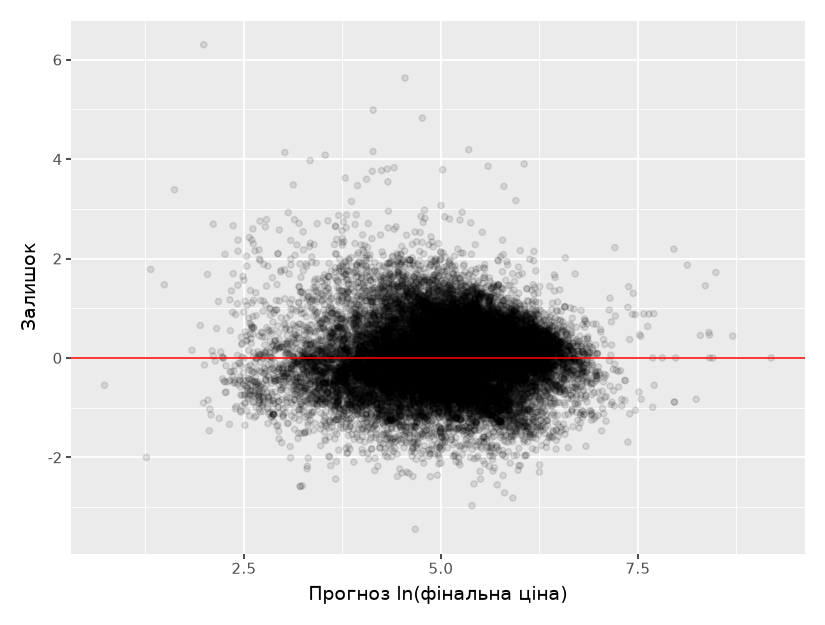

In [22]:
from statsmodels.stats.diagnostic import het_breuschpagan

aux = pd.DataFrame({'const': 1,
                    'yhat': m3.fittedvalues,
                    'yhat2': m3.fittedvalues ** 2})
lm, lm_p, f, f_p = het_breuschpagan(m3.resid, aux)
print(f"LM = {lm:.1f}, p = {lm_p:.4f}")

res = pd.DataFrame({'fitted': m3.fittedvalues, 'resid': m3.resid})
(p9.ggplot(res, p9.aes('fitted', 'resid'))
 + p9.geom_point(alpha=0.1)
 + p9.geom_hline(yintercept=0, color='red')
 + p9.labs(x='Прогноз ln(фінальна ціна)', y='Залишок')
).show()

### 6.2 t-тести

Тести для моделі (3) з кластерними SE.

| $H_0$ | Зміст |
|---|---|
| $\beta_1 = 0$ | Старт не пов'язаний з фінальною ціною понад характеристики ділянки (тест H1) |
| $\beta_1+\beta_2 = 0$ | Загальна еластичність ціни за НГО дорівнює нулю |
| $\beta_1+\beta_2 = 1$ | Фінальна ціна пропорційна НГО |

$\beta_2$ — ефект НГО при фіксованому старті. Оскільки старт встановлюється як частка НГО ($\ln S = \ln c + \ln NGO$), зростання НГО на 1% супроводжується зростанням старту на 1%, і загальна еластичність ціни за НГО дорівнює $\beta_1+\beta_2$.

$SE(\hat\beta_1+\hat\beta_2) = \sqrt{\operatorname{Var}(\hat\beta_1)+\operatorname{Var}(\hat\beta_2)+2\operatorname{Cov}(\hat\beta_1,\hat\beta_2)}$ враховує від'ємну коваріацію оцінок, зумовлену сильною кореляцією $\ln S$ і $\ln NGO$.

In [23]:
hypotheses = ['ln_start = 0', 'ln_start + ln_ngo = 0', 'ln_start + ln_ngo = 1']

rows = []
for h in hypotheses:
    t = m3.t_test(h)
    ci = t.conf_int()[0]
    rows.append({'H0': h,
                 'оцінка': float(np.squeeze(t.effect)),
                 'SE': float(np.squeeze(t.sd)),
                 't': float(np.squeeze(t.tvalue)),
                 'p': float(np.squeeze(t.pvalue)),
                 'ДІ 2.5%': ci[0],
                 'ДІ 97.5%': ci[1]})

pd.DataFrame(rows).round(4)

,H0,оцінка,SE,t,p,ДІ 2.5%,ДІ 97.5%
0,ln_start = 0,0.5603,0.0510,10.9821,0.0,0.4603,0.6603
1,ln_start + ln_ngo = 0,0.6288,0.0291,21.6080,0.0,0.5718,0.6858
2,ln_start + ln_ngo = 1,0.6288,0.0291,-12.7561,0.0,0.5718,0.6858


### 6.3 Перевірки стійкості

Модель (3) перераховано з однією зміною в кожному рядку; порівнюється $\hat\beta_1$.

**Вибірка:**
- (a) без аукціонів, де фінальна ціна перевищує стартову не більше ніж на 1% (торгу фактично не було, $\ln P \approx \ln S$ механічно);
- (b) без аукціонів з відношенням фінальна/стартова поза 1–99 перцентилями;
- (c) без громад з одним аукціоном;
- (d) без прифронтових областей (Донецька, Луганська, Запорізька, Херсонська, Харківська, Миколаївська): ризики замінування й окупації можуть впливати і на ціну, і на встановлення старту;
- (e) лише перші виставлення: при повторному виставленні старт зазвичай знижують, тож перевіряється, чи не ідентифікується $\beta_1$ лише з повторних аукціонів;
- (f) лише аукціони після 24.02.2022; оцінка лише для довоєнного періоду (~1 000 аукціонів) наведена для довідки;
- (g) без ділянок площею менше 1 га: ціна за гектар на малих ділянках дуже шумна;
- (h) без однієї області по черзі (leave-one-out): чи не визначає результат одна область.

**Специфікація:**
- (i) ціни в гривнях замість доларів;
- (j) кластеризація SE за областю (~23 кластери; при малій кількості кластерів SE можуть бути заниженими).


In [24]:
f3 = 'ln_final ~ ln_start + ' + hedonic + ' + C(org)'

def robust_fit(data, groups='org'):
    # factorize, бо statsmodels потребує числові коди кластерів
    g = pd.factorize(data[groups])[0]
    m = smf.ols(f3, data=data).fit(cov_type='cluster', cov_kwds={'groups': g})
    return {'β1': m.params['ln_start'], 'SE': m.bse['ln_start'],
            'p': m.pvalues['ln_start'], 'N': int(m.nobs)}

# умови для підвибірок
date = pd.to_datetime(df['Дата аукціону'])
area = df['Площа земельної ділянки, ГА']
n_org = df.groupby('org')['org'].transform('size')
q1, q99 = df['final_start'].quantile([0.01, 0.99])

frontline = ['Донецька + Луганська', 'Запорізька область', 'Херсонська область',
             'Харківська область', 'Миколаївська область']

no_bid = df['final_start'] <= 1.01
print(f"Частка аукціонів з final/start ≤ 1.01: {no_bid.mean():.1%}")

# гривні: ціни за гектар без перерахунку курсом
df_uah = df.assign(ln_final=np.log(df['Дохід'] / area),
                   ln_start=np.log(df['Виставлена вартість'] / area),
                   ln_ngo=np.log(df['Нормативна грошова оцінка'] / area))

results = {
    'Основна (3)':                    robust_fit(df),
    '(a) без final/start ≤ 1.01':     robust_fit(df[~no_bid]),
    '(b) p1–p99 final/start':         robust_fit(df[df['final_start'].between(q1, q99)]),
    '(c) без одиничних громад':       robust_fit(df[n_org > 1]),
    '(d) без прифронтових областей':  robust_fit(df[~df['oblast_group'].isin(frontline)]),
    '(e) лише перші виставлення':     robust_fit(df[df['relisting_group'] == '1']),
    '(f) після 24.02.2022':           robust_fit(df[date >= '2022-02-24']),
    '(f) до 24.02.2022 (довідково)':  robust_fit(df[date < '2022-02-24']),
    '(g) площа ≥ 1 га':               robust_fit(df[area >= 1]),
    '(i) у гривнях':                  robust_fit(df_uah),
    '(j) кластери за областю':        robust_fit(df, groups='oblast_group'),
}
pd.DataFrame(results).T.round(4)

Частка аукціонів з final/start ≤ 1.01: 1.4%


<positron-console-cell-24>:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.


,β1,SE,p,N
Основна (3),0.5603,0.0510,0.0,22253.0
(a) без final/start ≤ 1.01,0.5505,0.0517,0.0,21952.0
(b) p1–p99 final/start,0.6198,0.0503,0.0,21807.0
(c) без одиничних громад,0.5603,0.0509,0.0,22147.0
(d) без прифронтових областей,0.5501,0.0502,0.0,20417.0
(e) лише перші виставлення,0.5470,0.0570,0.0,17335.0
(f) після 24.02.2022,0.5559,0.0497,0.0,21245.0
(f) до 24.02.2022 (довідково),1.1737,0.2578,0.0,1008.0
(g) площа ≥ 1 га,0.5208,0.0540,0.0,20189.0
(i) у гривнях,0.5600,0.0511,0.0,22253.0


In [25]:
# (h) leave-one-out за областями
loo = {ob: robust_fit(df[df['oblast_group'] != ob]) for ob in df['oblast_group'].unique()}
loo = pd.DataFrame(loo).T.sort_values('β1').round(4)
loo

,β1,SE,p,N
Кіровоградська область,0.5443,0.0497,0.0,21527.0
Полтавська область,0.5458,0.0527,0.0,20717.0
Черкаська область,0.5506,0.0532,0.0,20504.0
Сумська область,0.5527,0.0522,0.0,20558.0
Харківська область,0.5544,0.0499,0.0,21342.0
Рівненська область,0.5557,0.0521,0.0,21338.0
Одеська область,0.5561,0.0531,0.0,19147.0
Дніпропетровська область,0.5564,0.0513,0.0,21748.0
Житомирська область,0.5566,0.0515,0.0,20984.0
Волинська область,0.5571,0.0568,0.0,20710.0
